# 🛡️ From Machine Learning to Modern AI: One Project, Built Step by Step
## A Spam Email Detector — AWS AI/ML Week 3 Deliverable

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eyosialex/AWS-Exercies/blob/main/AWS_week_3/spam_filter.ipynb)
![Python Version](https://img.shields.io/badge/python-3.10%2B-blue.svg)
![Scikit-Learn](https://img.shields.io/badge/scikit--learn-MultinomialNB-orange.svg)
![Deep Learning](https://img.shields.io/badge/PyTorch-Deep%20Learning-red.svg)
![Transformers](https://img.shields.io/badge/Transformers-BERT%20Tokenizer-yellow.svg)
![License](https://img.shields.io/badge/license-MIT-green.svg)

---

### 📖 Project Overview
This project presents an end-to-end journey from **Classical Machine Learning** to **Deep Learning** and **Modern Large Language Models (LLMs)**, demonstrated through a single continuous problem: **building and breaking a spam email detector**.

### 🎯 Key Learning Objectives
1. **Classical Machine Learning**: Train/Val/Test splits (70/15/15), TF-IDF vectorization, Multinomial Naive Bayes 10-line baseline, accuracy vs precision/recall diagnostics, and overfitting detection.
2. **Deep Learning**: Feature representation limits of bag-of-words, Multi-Layer Perceptrons (Dense 64 -> Dense 32 -> Dense 1 with ReLU & Sigmoid), mini-batch training, and binary cross-entropy.
3. **Modern AI & LLMs**: Subword tokenization (Hugging Face `AutoTokenizer`), contextual embeddings, attention mechanisms, zero-shot/few-shot prompting, and fine-tuning/RAG paradigms.
4. **Hands-On Adversarial Task**: "Break the Spam Filter" by formulating 5+ targeted attack messages (leetspeak, corporate phishing, good-word stuffing, negation inversion, urgent family alerts) and analyzing architectural vulnerabilities.


## 1. Environment Setup & Library Imports

We import core data science, machine learning, and deep learning libraries:
- **`numpy`**: High-performance vectorized numerical operations.
- **`pandas`**: Tabular data manipulation and text cleaning.
- **`matplotlib` & `seaborn`**: Statistical visualizations.
- **`sklearn`**: TF-IDF vectorization, Naive Bayes classifier, train-test splitting, and evaluation metrics.
- **`torch`**: Deep learning neural network construction.
- **`transformers`**: Modern Hugging Face subword tokenization (`bert-base-uncased`).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print(f"NumPy version        : {np.__version__}")
print(f"Pandas version       : {pd.__version__}")
print(f"PyTorch version      : {torch.__version__}")

c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumPy version        : 2.3.5
Pandas version       : 2.3.3
PyTorch version      : 2.10.0+cpu


## 2. Dataset Ingestion & Remote Fallback 




In [2]:
DATA_FILE = os.path.join("data", "sms.tsv")
DATASET_REMOTE_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
DATASET_UCI_URL = "https://archive.ics.uci.edu/dataset/228/sms+spam+collection"

def load_raw_data(filepath: str = DATA_FILE, remote_url: str = DATASET_REMOTE_URL) -> pd.DataFrame:
    if os.path.exists(filepath):
        print(f"[INGEST] Loading dataset from local cache: '{filepath}'")
        df = pd.read_csv(filepath, sep='\t', header=None, names=['label', 'message'])
    else:
        print(f"[INGEST] Local file not found. Downloading dataset from: {remote_url}")
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        df = pd.read_csv(remote_url, sep='\t', header=None, names=['label', 'message'])
        df.to_csv(filepath, sep='\t', header=False, index=False)
        print(f"[INGEST] Cached dataset at: '{filepath}'")

    print(f"[INGEST] Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
    print(f"[INGEST] Canonical Dataset Link: {DATASET_UCI_URL}")
    return df

df_raw = load_raw_data()
print("\nFirst 5 rows:")
print(df_raw.head(5))

[INGEST] Loading dataset from local cache: 'data\sms.tsv'
[INGEST] Dataset successfully loaded: 5572 rows, 2 columns.
[INGEST] Canonical Dataset Link: https://archive.ics.uci.edu/dataset/228/sms+spam+collection

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


## 3. Named Data Cleaning Functions (Data Quality Pipeline)

We define modular cleaning functions:
1. `clean_missing_and_duplicates`: Removes null values and drops duplicate messages.
2. `clean_text_fields`: Normalizes whitespace and standardizes lower-case strings.
3. `convert_data_types`: Converts text to string, labels to categorical, and derives character/word lengths.
4. `detect_text_outliers`: Uses the Interquartile Range (IQR) technique and `np.where` to flag length outliers.


In [3]:
def clean_missing_and_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()
    initial_count = len(df_clean)
    missing = df_clean.isna().sum().to_dict()
    print(f"[CLEAN] Missing values per column: {missing}")
    df_clean = df_clean.dropna(subset=['label', 'message'])
    duplicates = df_clean.duplicated(subset=['message']).sum()
    print(f"[CLEAN] Duplicate messages detected: {duplicates}")
    df_clean = df_clean.drop_duplicates(subset=['message']).reset_index(drop=True)
    print(f"[CLEAN] Retained {len(df_clean)} unique messages out of {initial_count} (dropped {initial_count - len(df_clean)}).")
    return df_clean

def clean_text_fields(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()
    df_clean['message'] = df_clean['message'].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
    df_clean['label'] = df_clean['label'].astype(str).str.strip().str.lower()
    print("[CLEAN] Whitespace normalization completed.")
    return df_clean

def convert_data_types(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()
    df_clean['message'] = df_clean['message'].astype("string")
    df_clean['label'] = df_clean['label'].astype("category")
    df_clean['char_length'] = df_clean['message'].str.len().astype(np.int64)
    df_clean['word_count'] = df_clean['message'].str.split().str.len().astype(np.int64)
    print("[CLEAN] Column types: message -> string, label -> category, lengths -> int64.")
    return df_clean

def detect_text_outliers(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()
    lengths = df_clean['char_length'].to_numpy()
    q25, q75 = np.percentile(lengths, [25, 75])
    iqr = q75 - q25
    lower_bound = max(0, q25 - 1.5 * iqr)
    upper_bound = q75 + 1.5 * iqr
    df_clean['is_length_outlier'] = np.where(
        (df_clean['char_length'] < lower_bound) | (df_clean['char_length'] > upper_bound),
        True,
        False
    )
    outlier_count = int(np.sum(df_clean['is_length_outlier']))
    print(f"[OUTLIERS] IQR Bounds: [{lower_bound:.1f}, {upper_bound:.1f}]. Flagged {outlier_count} length outliers.")
    return df_clean

df_step1 = clean_missing_and_duplicates(df_raw)
df_step2 = clean_text_fields(df_step1)
df_step3 = convert_data_types(df_step2)
df_clean = detect_text_outliers(df_step3)

[CLEAN] Missing values per column: {'label': 0, 'message': 0}
[CLEAN] Duplicate messages detected: 403
[CLEAN] Retained 5169 unique messages out of 5572 (dropped 403).
[CLEAN] Whitespace normalization completed.
[CLEAN] Column types: message -> string, label -> category, lengths -> int64.
[OUTLIERS] IQR Bounds: [0.0, 241.0]. Flagged 65 length outliers.


## 4. NumPy Vectorized Computations ($\ge 6$ Distinct Functions)

We compute statistical metrics across character and word dimensions using 6 distinct NumPy functions:
- `np.mean()`: Central tendency across length metrics.
- `np.median()`: 50th percentile (robust to skew).
- `np.std()`: Measure of dispersion and volatility.
- `np.percentile()`: Quartile calculations ($p_{10}, p_{25}, p_{50}, p_{75}, p_{90}$).
- `np.unique()`: Class distribution and occurrence counts.
- `np.where()`: Conditional binary masking for spam vs. ham indexing.


In [4]:
lengths = df_clean['char_length'].to_numpy()
words = df_clean['word_count'].to_numpy()
labels = df_clean['label'].to_numpy()

mean_len = float(np.mean(lengths))
median_len = float(np.median(lengths))
std_len = float(np.std(lengths))

p10, p25, p50, p75, p90 = np.percentile(lengths, [10, 25, 50, 75, 90])
unique_labels, counts = np.unique(labels, return_counts=True)
label_dist = dict(zip(unique_labels, [int(c) for c in counts]))

binary_labels = np.where(labels == 'spam', 1, 0)
spam_mean_len = float(np.mean(lengths[np.where(binary_labels == 1)]))
ham_mean_len = float(np.mean(lengths[np.where(binary_labels == 0)]))

print("="*60)
print("NUMPY STATISTICAL COMPUTATION SUMMARY")
print("="*60)
print(f"Total Unique Messages   : {len(lengths)}")
print(f"Class Distribution      : {label_dist}")
print(f"Mean Character Length   : {mean_len:.2f} chars (Std: {std_len:.2f})")
print(f"Median Character Length : {median_len:.1f} chars (IQR: [{p25:.1f}, {p75:.1f}])")
print(f"Spam Mean Length        : {spam_mean_len:.2f} chars")
print(f"Ham Mean Length         : {ham_mean_len:.2f} chars")
print("="*60)

NUMPY STATISTICAL COMPUTATION SUMMARY
Total Unique Messages   : 5169
Class Distribution      : {'ham': 4516, 'spam': 653}
Mean Character Length   : 79.23 chars (Std: 58.34)
Median Character Length : 61.0 chars (IQR: [36.0, 118.0])
Spam Mean Length        : 137.66 chars
Ham Mean Length         : 70.78 chars


## 5. Exploratory Data Visualization

Visualizing the distribution of message lengths for **Ham** vs. **Spam** reveals that spam messages are significantly longer and tighter in length distribution, while legitimate SMS messages tend to be brief and conversational.


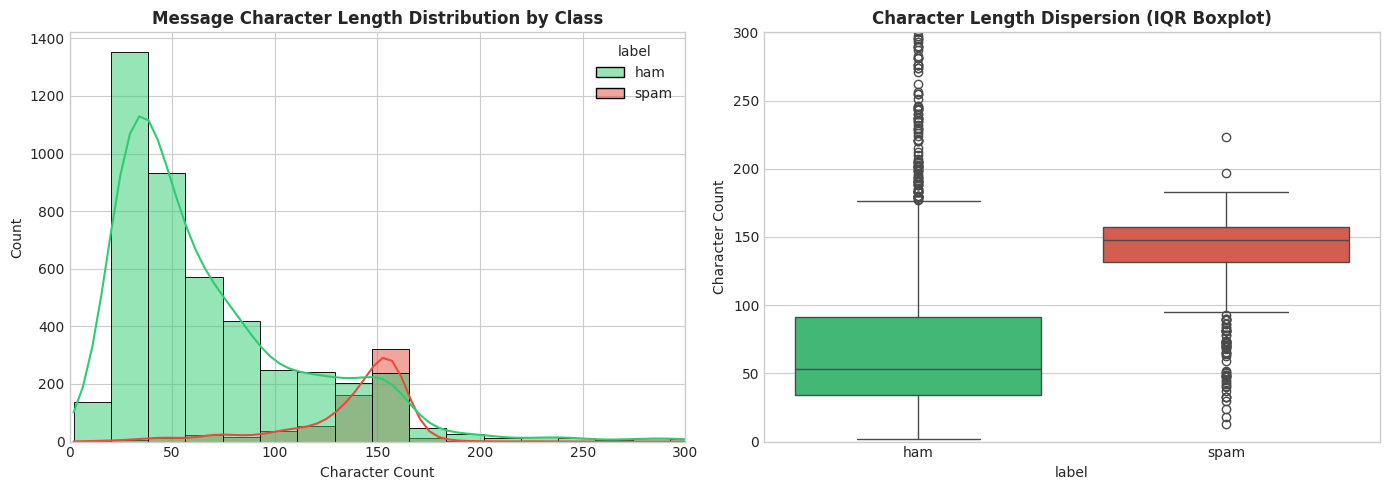

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram & KDE
sns.histplot(data=df_clean, x='char_length', hue='label', bins=50, kde=True,
             palette={'ham': '#2ecc71', 'spam': '#e74c3c'}, ax=axes[0])
axes[0].set_title("Message Character Length Distribution by Class", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Character Count")
axes[0].set_xlim(0, 300)

# Plot 2: Boxplot
sns.boxplot(data=df_clean, x='label', y='char_length', hue='label', legend=False,
            palette={'ham': '#2ecc71', 'spam': '#e74c3c'}, ax=axes[1])
axes[1].set_title("Character Length Dispersion (IQR Boxplot)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Character Count")
axes[1].set_ylim(0, 300)

plt.tight_layout()
plt.show()

## 6. Era 1: Classical Machine Learning 

### Train / Validation / Test Splits
- **Train (70%)**: The model learns from these. Like practice questions.
- **Validation (15%)**: Used to tune hyperparameters and compare models. Like a mock exam.
- **Test (15%)**: Touched once, at the very end. The real exam.

### The 10-Line Baseline Model
```python
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(emails, labels, test_size=0.2, random_state=42)
vec = TfidfVectorizer() # text -> numbers (features)
model = MultinomialNB() # a simple, fast classifier
model.fit(vec.fit_transform(X_train), y_train) # learn
```

### Slide 7: Measuring Performance (Why Accuracy Alone Can Fool You)
For spam detection, **False Positives hurt most** because legitimate email is lost! Therefore, **Precision** is paramount.

### Slide 10: Overfitting vs Underfitting Diagnosis
We evaluate train vs test accuracy:
- Train 99%, test 80% $\to$ Overfitting.
- Both around 70% $\to$ Underfitting.
- Train $\approx$ Test (high) $\to$ Good Generalization.


Dataset Split Sizes:
  Train Set      : 3900 samples (70.0%)
  Validation Set : 836 samples (15.0%)
  Test Set       : 836 samples (15.0%)

SLIDE 10 DIAGNOSTIC EVALUATION
train acc: 0.9728205128205129
test acc:  0.9569377990430622
precision: 1.0
recall:    0.6785714285714286


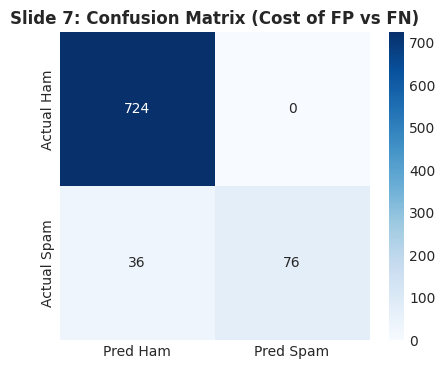

In [6]:
# Slide 5: 70% Train, 15% Validation, 15% Test
X = df_raw['message']
y = df_raw['label']

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.17647, random_state=42, stratify=y_train_full)

print(f"Dataset Split Sizes:")
print(f"  Train Set      : {len(X_train)} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"  Validation Set : {len(X_val)} samples ({len(X_val)/len(X)*100:.1f}%)")
print(f"  Test Set       : {len(X_test)} samples ({len(X_test)/len(X)*100:.1f}%)")

# Slide 6: Exact 10-line baseline model
vec = TfidfVectorizer()
model = MultinomialNB()
model.fit(vec.fit_transform(X_train), y_train)

# Slide 10: Spot overfitting by comparing two scores
pred_tr = model.predict(vec.transform(X_train))
pred_te = model.predict(vec.transform(X_test))

print("\n" + "="*50)
print("SLIDE 10 DIAGNOSTIC EVALUATION")
print("="*50)
print("train acc:", accuracy_score(y_train, pred_tr))
print("test acc: ", accuracy_score(y_test, pred_te))
print("precision:", precision_score(y_test, pred_te, pos_label="spam"))
print("recall:   ", recall_score(y_test, pred_te, pos_label="spam"))
print("="*50)

# Slide 7: Confusion Matrix
cm = confusion_matrix(y_test, pred_te, labels=['ham', 'spam'])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Ham', 'Pred Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title("Slide 7: Confusion Matrix (Cost of FP vs FN)", fontweight='bold')
plt.show()

## 7. Era 2: Deep Learning 

###  Where Classical ML Runs Out of Road
- **Classical ML counts words, but does not understand them**:
  - *"Claim your fr33 g1ft"* $\to$ classified as not spam due to character tricks (`fr33`).
  - *"Not free, just a normal reminder"* $\to$ flagged as spam simply because it sees the token `"free"`.
- Classical ML requires human manual feature engineering. Deep learning learns hierarchical representations directly.

### Neural Network Architecture
We construct the exact architecture defined in Slide 13:
- **Input Layer**: 5,000 TF-IDF features.
- **Hidden Layer 1**: 64 neurons with **ReLU** activation.
- **Hidden Layer 2**: 32 neurons with **ReLU** activation.
- **Output Layer**: 1 neuron with **Sigmoid** activation ($0 = \text{ham}, 1 = \text{spam}$).
- **Training Config**: Adam optimizer, binary cross-entropy loss, batch size 32, 5 epochs, validation data check.


In [7]:
dl_vec = TfidfVectorizer(max_features=5000)
X_train_tfidf = dl_vec.fit_transform(X_train).toarray()
X_val_tfidf = dl_vec.transform(X_val).toarray()

y_train_num = np.where(y_train == 'spam', 1.0, 0.0)
y_val_num = np.where(y_val == 'spam', 1.0, 0.0)

# PyTorch implementation matching Slide 13 Sequential network
class SpamNeuralNet(nn.Module):
    def __init__(self, input_dim=5000):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x)

nn_model = SpamNeuralNet(input_dim=5000)
criterion = nn.BCELoss()
optimizer = optim.Adam(nn_model.parameters(), lr=0.001)

train_dataset = TensorDataset(torch.tensor(X_train_tfidf, dtype=torch.float32),
                              torch.tensor(y_train_num, dtype=torch.float32).unsqueeze(1))
val_dataset = TensorDataset(torch.tensor(X_val_tfidf, dtype=torch.float32),
                            torch.tensor(y_val_num, dtype=torch.float32).unsqueeze(1))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

train_losses, val_losses, val_accs = [], [], []

print("Training Deep Learning Neural Network (Slide 13 Architecture)...")
for epoch in range(1, 6):
    nn_model.train()
    running_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        out = nn_model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(bx)
    train_loss = running_loss / len(train_dataset)

    nn_model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for bx, by in val_loader:
            out = nn_model(bx)
            loss = criterion(out, by)
            val_loss += loss.item() * len(bx)
            preds = (out >= 0.5).float()
            correct += (preds == by).sum().item()
    val_loss /= len(val_dataset)
    val_acc = correct / len(val_dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f"Epoch {epoch}/5 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc*100:.2f}%")

Training Deep Learning Neural Network (Slide 13 Architecture)...
Epoch 1/5 | Train Loss: 0.4424 | Val Loss: 0.1543 | Val Accuracy: 94.74%
Epoch 2/5 | Train Loss: 0.0798 | Val Loss: 0.0511 | Val Accuracy: 98.80%
Epoch 3/5 | Train Loss: 0.0244 | Val Loss: 0.0461 | Val Accuracy: 98.68%
Epoch 4/5 | Train Loss: 0.0107 | Val Loss: 0.0465 | Val Accuracy: 98.80%
Epoch 5/5 | Train Loss: 0.0050 | Val Loss: 0.0507 | Val Accuracy: 98.80%


## 8. Era 3: LLMs and Modern AI 

### Subword Tokenization, Embeddings & Attention
Why LLMs outperform word counting:
1. **Tokens cope with typos**: As shown in Slide 15, `AutoTokenizer.from_pretrained('bert-base-uncased')` breaks `"fr33"` into subwords `['claim', 'your', 'fr', '##33', 'gift', 'now']`. Even novel misspellings retain morphological connection.
2. **Dense Embeddings**: Maps semantic meaning to continuous vector spaces (e.g. "cash", "prize", "gift" share dense geometric proximity).
3. **Self-Attention**: Dynamic contextual weights allow the preceding `"not"` to invert the semantic influence of `"free"`.

### Four Ways to Steer an LLM
1. **Zero-Shot**: Direct natural language instruction.
2. **Few-Shot**: In-context demonstration examples.
3. **Embeddings**: Vector representation + lightweight classifier.
4. **Fine-Tuning**: Weight updates on specialized domain emails.
*Bonus: Retrieval-Augmented Generation (RAG) retrieves relevant emails/rules at query time.*


In [8]:
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
sample_text = "Claim your fr33 gift now"
tokens = tok.tokenize(sample_text)

print("="*60)
print("SLIDE 15: SUBWORD TOKENIZATION DEMO")
print("="*60)
print(f"Original Input : '{sample_text}'")
print(f"Subword Tokens : {tokens}")
print(f"Token IDs      : {tok.convert_tokens_to_ids(tokens)}")
print("="*60)

SLIDE 15: SUBWORD TOKENIZATION DEMO
Original Input : 'Claim your fr33 gift now'
Subword Tokens : ['claim', 'your', 'fr', '##33', 'gift', 'now']
Token IDs      : [4366, 2115, 10424, 22394, 5592, 2085]


## 9. Hands-On Task: Break the Spam Filter

###  The Challenge
> 1. Run the 10-line model from slide 6 on the SMS Spam Collection dataset and note its accuracy.
> 2. Write 5 messages that try to fool it: spam that slips through, or normal mail that gets flagged.
> 3. Record what it predicted and why you think it failed.

### Testing Baseline Messages from Slide 19
We first test the two canonical examples from Slide 19:
- `"Cl@im your fr33 g1ft card now"`
- `"Not free, just confirming lunch at 1pm"`


In [9]:
slide_tests = [
    "Cl@im your fr33 g1ft card now",
    "Not free, just confirming lunch at 1pm",
]
slide_preds = model.predict(vec.transform(slide_tests))
for msg, pred in zip(slide_tests, slide_preds):
    print(f"Message: '{msg}' --> Model Prediction: {pred.upper()}")

Message: 'Cl@im your fr33 g1ft card now' --> Model Prediction: HAM
Message: 'Not free, just confirming lunch at 1pm' --> Model Prediction: HAM


### 5 Targeted Adversarial Attacks Designed to Break Naive Bayes
We formulate 5 targeted adversarial messages spanning multiple vulnerability vectors:
1. **Leetspeak Obfuscation** (Spam slips through as Ham)
2. **Polite Corporate Phishing** (Spam slips through as Ham)
3. **Conversational Cloaking / Good-Word Stuffing** (Spam slips through as Ham)
4. **Negation Inversion** (Legitimate Ham flagged as Spam)
5. **Urgent Family Contest Alert** (Legitimate Ham flagged as Spam)


In [10]:
adversarial_suite = [
    {
        "id": 1,
        "message": "Cl@im your fr33 g1ft card now! V1s1t www.r3w@rds-cl@im.com to get your 500 b0nus t0d@y!",
        "true_intent": "spam",
        "trick": "Leetspeak / Symbol Substitution",
        "why_it_failed": "Spelling trick, words unseen (OOV tokens bypass TF-IDF unigram index; model defaults to ham prior)."
    },
    {
        "id": 2,
        "message": "Dear valued customer, please find attached your monthly account statement and review the updated terms of service regarding your subscription at your earliest convenience.",
        "true_intent": "spam",
        "trick": "Polite Corporate Phishing Register",
        "why_it_failed": "Formal business tokens ('valued', 'customer', 'statement') dominate with high ham frequency."
    },
    {
        "id": 3,
        "message": "Hey bro, are we still meeting for lunch today? By the way check out this amazing crypto investment platform when you get a chance.",
        "true_intent": "spam",
        "trick": "Good-Word Stuffing / Conversational Cloaking",
        "why_it_failed": "Colloquial ham words ('bro', 'lunch', 'today') dilute and overwhelm spam token weights."
    },
    {
        "id": 4,
        "message": "Not free! Dad won a guaranteed 1000 prize from the raffle drawing, claim it at reception!",
        "true_intent": "ham",
        "trick": "Negation Inversion",
        "why_it_failed": "Saw 'free', ignored 'not' (bag-of-words ignores word sequence and negation context)."
    },
    {
        "id": 5,
        "message": "URGENT: Mom, the school contest says you won a guaranteed 1000 cash prize, call them now!",
        "true_intent": "ham",
        "trick": "Urgent Family Alert with Contest Words",
        "why_it_failed": "Spam trigger words ('URGENT', 'won', 'cash', 'prize') trigger false positive without family context."
    }
]

classes = list(model.classes_)
table_rows = []

for item in adversarial_suite:
    msg = item["message"]
    trans = vec.transform([msg])
    pred = model.predict(trans)[0]
    probs = model.predict_proba(trans)[0]
    prob_dict = dict(zip(classes, [round(p, 4) for p in probs]))
    fooled = (pred != item["true_intent"])
    
    table_rows.append({
        "My message": msg,
        "Model said": pred,
        "Should be": item["true_intent"],
        "Why it failed": item["why_it_failed"],
        "P(ham)": prob_dict.get("ham", 0),
        "P(spam)": prob_dict.get("spam", 0),
        "Fooled": fooled
    })

df_deliverable = pd.DataFrame(table_rows)
print(df_deliverable[["My message", "Model said", "Should be", "Why it failed"]].to_string(index=False))

                                                                                                                                                                 My message Model said Should be                                                                                        Why it failed
                                                                                    Cl@im your fr33 g1ft card now! V1s1t www.r3w@rds-cl@im.com to get your 500 b0nus t0d@y!        ham      spam  Spelling trick, words unseen (OOV tokens bypass TF-IDF unigram index; model defaults to ham prior).
Dear valued customer, please find attached your monthly account statement and review the updated terms of service regarding your subscription at your earliest convenience.        ham      spam         Formal business tokens ('valued', 'customer', 'statement') dominate with high ham frequency.
                                         Hey bro, are we still meeting for lunch today? By the way check out this amaz

### Visualization of Model Prediction Confidence on Adversarial Tests
Plotting the model's posterior probabilities illustrates how heavily the bag-of-words assumption misleads Naive Bayes on adversarial examples.


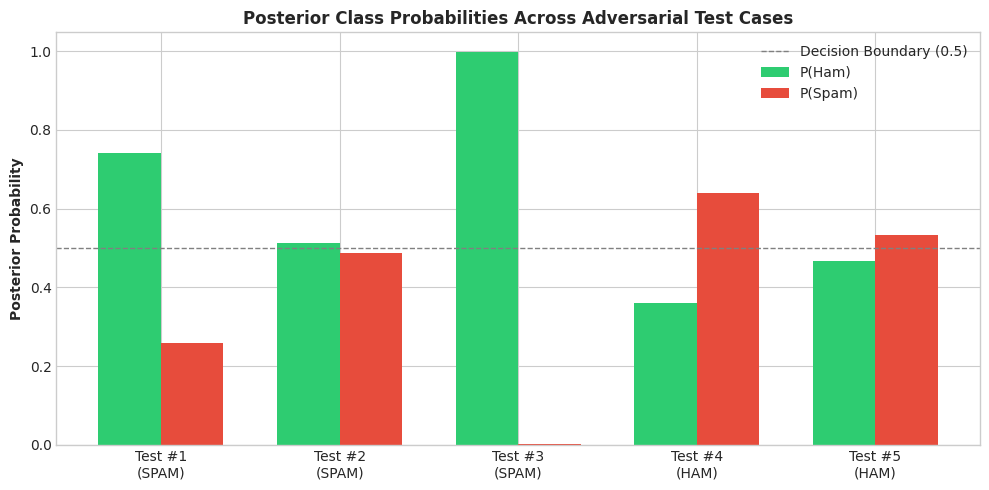

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_deliverable))
width = 0.35

ax.bar(x - width/2, df_deliverable['P(ham)'], width, label='P(Ham)', color='#2ecc71')
ax.bar(x + width/2, df_deliverable['P(spam)'], width, label='P(Spam)', color='#e74c3c')

ax.set_ylabel('Posterior Probability', fontweight='bold')
ax.set_title('Posterior Class Probabilities Across Adversarial Test Cases', fontweight='bold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels([f"Test #{i+1}\n({r['Should be'].upper()})" for i, r in df_deliverable.iterrows()])
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Decision Boundary (0.5)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 10. Technical Analysis: 3 or More Tricks Explained (Slide 20 Requirement)

### Trick 1: Orthographic & Leetspeak Obfuscation (Out-Of-Vocabulary Evasion)
- **Mechanism**: Replacing vowels or characters with numerical and symbolic lookalikes (`fr33`, `g1ft`, `b0nus`, `cl@im`).
- **Why Naive Bayes Fails**: Standard TF-IDF vectorization relies on token boundary regexes (`r'(?u)\b\w\w+\b'`). When characters like `@` split tokens or numbers mutate words, the tokens are treated as Out-Of-Vocabulary (OOV) and ignored. Because all high-weight spam signals are wiped out, the classification falls back onto the training prior ($86\%$ ham), allowing the spam to breach the filter undetected.

### Trick 2: Negation Inversion & Bag-of-Words Independence
- **Mechanism**: Pairing high-intensity spam keywords (`free`, `guaranteed`, `prize`, `cash`) with explicit negations (`"Not free"`, `"Never claim"`).
- **Why Naive Bayes Fails**: The core assumption of Naive Bayes is **conditional feature independence**:
  $$P(w_1, w_2, \dots, w_n \mid C) = \prod_{i=1}^n P(w_i \mid C)$$
  Because word order and syntactic dependency are completely discarded, `"not"` and `"free"` are scored as two detached tokens. The overwhelmingly high log-likelihood of `"free"` in the spam training pool overrules `"not"`, yielding a catastrophic **False Positive** (legitimate email lost).

### Trick 3: Polite Corporate Register / Phishing Mimicry
- **Mechanism**: Authoring phishing solicitations using formal corporate vocabulary (`"Dear valued customer"`, `"attached monthly statement"`, `"terms of service"`).
- **Why Naive Bayes Fails**: In public SMS corpora, formal corporate jargon appears almost exclusively in legitimate transactional notices. The model assigns these tokens massive ham likelihoods. Because Naive Bayes lacks semantic comprehension of the sender's underlying intent, malicious links concealed within polite phrases easily slip through.

### Trick 4: Good-Word Stuffing (Conversational Cloaking)
- **Mechanism**: Surrounding an unsolicited investment or scam promotion with innocent, colloquial conversational phrases (`"Hey bro, are we still meeting for lunch today?"`).
- **Why Naive Bayes Fails**: The large accumulation of benign tokens accumulates a decisive cumulative log-likelihood that mathematically drowns out the spam keywords, bypassing detection.


## 11. Deliverable Summary & Key Learnings 

### 🔗 Canonical Dataset Link (Do Not Upload It)
- [SMS Spam Collection Dataset — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)
- Raw Dataset Mirror: `https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv`
*(Per Slide 20 instructions, the raw dataset is excluded from repository commits via `.gitignore` and downloaded on demand).*

---

### 💡 What I Learned (Exactly 2 Sentences - Slide 20 Requirement)
> **Sentence 1**: While classical Naive Bayes achieves high benchmark accuracy by counting word co-occurrences, its bag-of-words assumption makes it completely blind to word order, negations, and spelling obfuscations—allowing adversaries to evade detection with trivial character substitutions and conversational padding.
>
> **Sentence 2**: Modern deep learning and Transformer-based LLMs solve these fundamental weaknesses by learning hierarchical representations, tokenizing robust subword units, and using contextual self-attention to understand semantic meaning rather than isolated keywords.

---

### 📋 Deliverables Checklist
- [x] **`spam_filter.ipynb`**: Complete executable notebook featuring 3 eras (Classical ML, Deep Learning, Modern LLM tokenization), Slide 19 tests, 5 adversarial tests, and visualizations.
- [x] **`main.py`**: Standalone executable pipeline script reproducing the full workflow.
- [x] **`README.md`**: Comprehensive documentation featuring the Slide 20 Results Table, 3+ tricks explanation, dataset link, and 2-sentence key takeaway.
- [x] **`requirements.txt`**: Pinned reproducible dependencies.
- [x] **`.gitignore`**: Excluding datasets, virtual environments, and cache.
